# College Football Upset Vulnerability — Notebook 09: Offensive, Defensive & Matchup Efficiency



## 0. Load required project files



In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'
INPUTS = {
    'team_games': PROCESSED / 'team_games.csv',
    'matchups': PROCESSED / 'matchup_features_history_decay.csv',
    'history_manifest': PROCESSED / 'history_decay_feature_manifest.json',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'split_manifest': PROCESSED / 'split_manifest.json',
    'notebook07_oof': OUTPUT_DIR / 'history_decay_oof_predictions_2019_2023.csv',
}
missing = [f'{name}: {path}' for name,path in INPUTS.items() if not path.is_file()]
if missing:
    raise FileNotFoundError('Missing files; export Notebooks 02/07 first:\n' + '\n'.join(missing))
team_games = pd.read_csv(INPUTS['team_games'],parse_dates=['date'],low_memory=False)
matchups = pd.read_csv(INPUTS['matchups'],parse_dates=['date'],low_memory=False)
eligibility = pd.read_csv(INPUTS['eligibility'],low_memory=False)
history_manifest = json.loads(INPUTS['history_manifest'].read_text(encoding='utf-8'))
split_manifest = json.loads(INPUTS['split_manifest'].read_text(encoding='utf-8'))
prior_oof = pd.read_csv(INPUTS['notebook07_oof'])
folds = split_manifest['validation_folds']
TEST_SEASONS = set(map(int,split_manifest['test_seasons']))
BASE55 = list(history_manifest['feature_sets']['prior_3seasons_fade4'])
assert TEST_SEASONS == {2024,2025}
assert [int(f['validation_season']) for f in folds]==[2019,2020,2021,2022,2023]
assert len(BASE55)==55 and len(set(BASE55))==55
assert team_games.groupby('game_id').size().eq(2).all()
assert matchups.game_id.is_unique and eligibility.game_id.is_unique
assert len(team_games)==2*len(matchups)
assert set(BASE55).issubset(matchups.columns)
print(f'Loaded {len(team_games):,} team-games; {len(matchups):,} matchups.')
print('Baseline features:',len(BASE55),'| Validation:',[f['validation_season'] for f in folds])
print('Final holdout (not evaluated):',sorted(TEST_SEASONS))
print('pandas:',pd.__version__,'scikit-learn:',sklearn.__version__)

Mounted at /content/drive
Loaded 36,600 team-games; 18,300 matchups.
Baseline features: 55 | Validation: [2019, 2020, 2021, 2022, 2023]
Final holdout (not evaluated): [2024, 2025]
pandas: 2.2.3 scikit-learn: 1.6.1


## 1. Attach verified season-specific FBS membership


In [ ]:
needed = ['game_id','season','home','away','home_subdivision','away_subdivision']
assert set(needed).issubset(eligibility.columns)
tg = team_games.merge(eligibility[needed],on=['game_id','season'],how='left',validate='many_to_one',indicator=True)
assert tg['_merge'].eq('both').all()
tg.drop(columns='_merge',inplace=True)
flag = tg['designated_home'].astype('string').str.strip().str.lower()
assert flag.isin(['true','false','1','0']).all()
tg['designated_home'] = flag.isin(['true','1'])
assert (tg.team.to_numpy()==np.where(tg.designated_home,tg.home,tg.away)).all()
assert (tg.opponent.to_numpy()==np.where(tg.designated_home,tg.away,tg.home)).all()
tg['opponent_subdivision']=np.where(tg.designated_home,tg.away_subdivision,tg.home_subdivision)
tg['opponent_is_fbs']=tg.opponent_subdivision.eq('fbs')
tg=tg.sort_values(['team','season','date','game_id'],kind='stable').reset_index(drop=True)
assert tg.date.notna().all()
assert not tg.duplicated(['team','date']).any(), 'Same-day duplicate team appearances: revise chronological audit'
assert tg.groupby('game_id').size().eq(2).all()
print('Opponent subdivisions among team-games:')
display(tg.opponent_subdivision.value_counts(dropna=False).rename('team_games').to_frame())

Opponent subdivisions among team-games:


,team_games
opponent_subdivision,
fbs,34469
fcs,2105
unknown,25
d2,1


## 2. Create strictly pregame offensive & defensive statistics



In [ ]:
# Confirm fields exactly as exported by Notebook 02.
REQUIRED = ['points_for','points_against','total_yards_against',
    'total_yards_for','pass_yards_for','pass_yards_against',
    'pass_att_for','pass_att_against','pass_comp_for','pass_comp_against',
    'rush_yards_for','rush_yards_against','rush_att_for','rush_att_against',
    'third_down_comp_for','third_down_comp_against',
    'third_down_att_for','third_down_att_against',
    'int_for','int_against','pen_yards_for','pen_yards_against']
absent = sorted(set(REQUIRED)-set(tg.columns))
if absent:
    raise KeyError(f'Notebook 02 team_games.csv is missing box-score columns: {absent}')
for col in REQUIRED:
    tg[col] = pd.to_numeric(tg[col],errors='coerce')

KEYS=['team','season']
# Cumulative pregame mean from rows where the opponent was FBS and the statistic exists.
def earlier_fbs_mean(frame, source):
    valid = frame.opponent_is_fbs & frame[source].notna()
    contribution = frame[source].where(valid,0.0)
    prior_sum = contribution.groupby([frame.team,frame.season],sort=False).cumsum()-contribution
    n = valid.astype(int)
    prior_n = n.groupby([frame.team,frame.season],sort=False).cumsum()-n
    return (prior_sum / prior_n.replace(0,np.nan)).astype(float)

# Rates: same set of valid game observations for numerator and denominator.
def earlier_fbs_ratio(frame, numerator, denominator):
    num=frame[numerator]; den=frame[denominator]
    valid=frame.opponent_is_fbs & num.notna() & den.notna() & den.gt(0)
    x=num.where(valid,0.0); d=den.where(valid,0.0)
    group=[frame.team,frame.season]
    previous_x = x.groupby(group,sort=False).cumsum()-x
    previous_d = d.groupby(group,sort=False).cumsum()-d
    return (previous_x/previous_d.replace(0,np.nan)).astype(float)

# These are always pregame and only include games against verified FBS teams.
SCORING=['fbs_prior_points_for_pg','fbs_prior_points_against_pg']
for dest,source in [('fbs_prior_points_for_pg','points_for'),
                    ('fbs_prior_points_against_pg','points_against')]:
    tg[dest]=earlier_fbs_mean(tg,source)

EFFICIENCY=['fbs_prior_total_yards_against_pg']
tg['fbs_prior_total_yards_against_pg']=earlier_fbs_mean(tg,'total_yards_against')
for role in ['for','against']:
    rate_specs={
        f'fbs_prior_pass_ypa_{role}':(f'pass_yards_{role}',f'pass_att_{role}'),
        f'fbs_prior_rush_ypc_{role}':(f'rush_yards_{role}',f'rush_att_{role}'),
        f'fbs_prior_completion_rate_{role}':(f'pass_comp_{role}',f'pass_att_{role}'),
        f'fbs_prior_third_down_rate_{role}':(f'third_down_comp_{role}',f'third_down_att_{role}'),
    }
    for dest,(num,den) in rate_specs.items():
        tg[dest]=earlier_fbs_ratio(tg,num,den)
        EFFICIENCY.append(dest)
    # A box-score approximation of offensive/defensive yards per play; no play-by-play sacks correction.
    denom=f'_attempts_{role}'
    tg[denom]=tg[f'rush_att_{role}']+tg[f'pass_att_{role}']
    dest=f'fbs_prior_yards_per_play_{role}'
    tg[dest]=earlier_fbs_ratio(tg,f'total_yards_{role}',denom)
    EFFICIENCY.append(dest)

DISCIPLINE=[]
for role in ['for','against']:
    for stat in ['int','pen_yards']:
        dest=f'fbs_prior_{stat}_{role}_pg'
        tg[dest]=earlier_fbs_mean(tg,f'{stat}_{role}')
        DISCIPLINE.append(dest)

ALL_NEW_SIDE=SCORING+EFFICIENCY+DISCIPLINE
assert len(ALL_NEW_SIDE)==len(set(ALL_NEW_SIDE))
# A row with no prior recorded FBS opponent has no defined means/rates.
fbs_n=tg.opponent_is_fbs.astype(int)
tg['audit_prior_fbs_games']=fbs_n.groupby([tg.team,tg.season],sort=False).cumsum()-fbs_n
assert tg.loc[tg.audit_prior_fbs_games.eq(0),ALL_NEW_SIDE].isna().all().all()
assert (tg.audit_prior_fbs_games>=0).all()
print('New pregame team-level statistics:',len(ALL_NEW_SIDE), '(',len(SCORING),'scoring,',len(EFFICIENCY),'efficiency,',len(DISCIPLINE),'discipline)')
print('Coverage among team-game rows with ≥1 earlier FBS game:')
coverage=tg.loc[tg.audit_prior_fbs_games.ge(1),ALL_NEW_SIDE].notna().mean().sort_values()
display(coverage.to_frame('not_missing_fraction').round(3))
preview_cols=['date','opponent','opponent_subdivision','audit_prior_fbs_games',
              'fbs_prior_points_for_pg','fbs_prior_points_against_pg',
              'fbs_prior_pass_ypa_for','fbs_prior_pass_ypa_against',
              'fbs_prior_third_down_rate_for']
print('Kansas State 2025: pregame feature progression (all venues):')
display(tg.loc[tg.team.eq('Kansas State') & tg.season.eq(2025),preview_cols].head(13).round(3))

New pregame team-level statistics: 17 ( 2 scoring, 11 efficiency, 4 discipline)
Coverage among team-game rows with ≥1 earlier FBS game:


,not_missing_fraction
fbs_prior_third_down_rate_for,0.998
fbs_prior_third_down_rate_against,1.000
fbs_prior_rush_ypc_for,1.000
fbs_prior_pass_ypa_for,1.000
fbs_prior_yards_per_play_for,1.000
fbs_prior_completion_rate_for,1.000
fbs_prior_int_for_pg,1.000
fbs_prior_pen_yards_for_pg,1.000
fbs_prior_completion_rate_against,1.000
fbs_prior_rush_ypc_against,1.000


Kansas State 2025: pregame feature progression (all venues):


,date,opponent,opponent_subdivision,audit_prior_fbs_games,fbs_prior_points_for_pg,fbs_prior_points_against_pg,fbs_prior_pass_ypa_for,fbs_prior_pass_ypa_against,fbs_prior_third_down_rate_for
13001,2025-08-23,Iowa State,fbs,0,NaN,NaN,NaN,NaN,NaN
13002,2025-08-30,North Dakota,fcs,1,21.000,24.000,9.100,6.536,0.385
13003,2025-09-06,Army,fbs,1,21.000,24.000,9.100,6.536,0.385
13004,2025-09-12,Arizona,fbs,2,21.000,24.000,8.091,6.950,0.318
13005,2025-09-27,UCF,fbs,3,19.667,23.667,6.345,6.162,0.286
13006,2025-10-04,Baylor,fbs,4,23.250,22.750,6.373,6.530,0.327
13007,2025-10-11,TCU,fbs,5,25.400,25.200,6.699,7.180,0.375
13008,2025-10-25,Kansas,fbs,6,28.000,25.667,6.830,7.387,0.388
13009,2025-11-01,Texas Tech,fbs,7,30.000,24.429,7.407,6.776,0.378
13010,2025-11-15,Oklahoma State,fbs,8,28.750,26.750,7.211,6.902,0.390


## 3. Independent leakage audit (recalculate from previous games)



In [ ]:
def direct_prior_fbs(row):
    return tg.loc[(tg.team.eq(row.team)) & (tg.season.eq(row.season)) &
                  (tg.date.lt(row.date)) & (tg.opponent_is_fbs)]

def simple_ratio(frame,numerator,denominator):
    good=frame[numerator].notna() & frame[denominator].notna() & frame[denominator].gt(0)
    return frame.loc[good,numerator].sum()/frame.loc[good,denominator].sum() if good.any() else np.nan

def equal_or_both_na(a,b,atol=1e-8):
    return bool(np.isclose(a,b,atol=atol,rtol=1e-9,equal_nan=True))

pool=tg.loc[tg.audit_prior_fbs_games.ge(1)]
samples=pd.concat([tg.loc[tg.audit_prior_fbs_games.eq(0)].sample(n=min(20,(tg.audit_prior_fbs_games==0).sum()),random_state=9),
                   pool.sample(n=min(80,len(pool)),random_state=10)],ignore_index=True)
for row in samples.itertuples(index=False):
    prior=direct_prior_fbs(row)
    assert len(prior)==int(row.audit_prior_fbs_games)
    checks={
       'fbs_prior_points_for_pg':prior.points_for.mean(),
       'fbs_prior_points_against_pg':prior.points_against.mean(),
       'fbs_prior_total_yards_against_pg':prior.total_yards_against.mean(),
       'fbs_prior_pass_ypa_for':simple_ratio(prior,'pass_yards_for','pass_att_for'),
       'fbs_prior_rush_ypc_against':simple_ratio(prior,'rush_yards_against','rush_att_against'),
       'fbs_prior_third_down_rate_for':simple_ratio(prior,'third_down_comp_for','third_down_att_for'),
       'fbs_prior_int_for_pg':prior.int_for.mean(),
    }
    for name,expected in checks.items():
        got=getattr(row,name)
        assert equal_or_both_na(got,expected),(
            'Pregame audit mismatch',row.team,row.season,row.date,name,got,expected)
print(f'PASS: {len(samples)} independent pregame snapshots and 7 statistics per snapshot.')
print('PASS: Current-game box scores and same-day outcomes do not enter new features.')

PASS: 100 independent pregame snapshots and 7 statistics per snapshot.
PASS: Current-game box scores and same-day outcomes do not enter new features.


## 4. Construct matchup-side features and freeze the experimental feature sets



In [ ]:
JOIN=['game_id','season','home','away']
assert matchups.game_id.is_unique
expanded=matchups.copy()
for side in ['home','away']:
    side_rows=tg.loc[tg.designated_home.eq(side=='home'),['game_id','team',*ALL_NEW_SIDE]].copy()
    side_rows=side_rows.rename(columns={'team':side, **{x:f'{side}_{x}' for x in ALL_NEW_SIDE}})
    expanded=expanded.merge(side_rows,on=['game_id',side],how='left',validate='one_to_one',indicator=True)
    assert expanded['_merge'].eq('both').all()
    expanded.drop(columns='_merge',inplace=True)
assert len(expanded)==len(matchups) and expanded.game_id.is_unique

# For every side statistic, include home, away and the home-minus-away difference.
def side_and_diff(names):
    result=[]
    for name in names:
        left=f'home_{name}';right=f'away_{name}';difference=f'diff_{name}'
        expanded[difference]=expanded[left]-expanded[right]
        result.extend([left,right,difference])
    return result
SCORING_FEATURES=side_and_diff(SCORING)
EFFICIENCY_FEATURES=side_and_diff(EFFICIENCY)
DISCIPLINE_FEATURES=side_and_diff(DISCIPLINE)

# True cross-team interactions: offensive rate × opposing defensive rate allowed.
# Unlike a subtraction, a product is not a linear combination of the main-effect
# variables already present in plus_efficiency, so it tests a distinct hypothesis.
MATCHUP_FEATURES=[]
for metric in ['pass_ypa','rush_ypc','completion_rate','third_down_rate','yards_per_play']:
    h=f'home_fbs_prior_{metric}_for'; ad=f'away_fbs_prior_{metric}_against'
    a=f'away_fbs_prior_{metric}_for'; hd=f'home_fbs_prior_{metric}_against'
    hkey=f'matchup_home_{metric}_off_x_away_def'
    akey=f'matchup_away_{metric}_off_x_home_def'
    expanded[hkey]=expanded[h]*expanded[ad]
    expanded[akey]=expanded[a]*expanded[hd]
    MATCHUP_FEATURES.extend([hkey,akey])
assert len(MATCHUP_FEATURES)==10 and len(set(MATCHUP_FEATURES))==10

FEATURE_SETS={
    'fade4_baseline':BASE55,
    'plus_scoring':BASE55+SCORING_FEATURES,
    'plus_efficiency':BASE55+SCORING_FEATURES+EFFICIENCY_FEATURES,
    'plus_matchups':BASE55+SCORING_FEATURES+EFFICIENCY_FEATURES+MATCHUP_FEATURES,
    'plus_discipline':BASE55+SCORING_FEATURES+EFFICIENCY_FEATURES+MATCHUP_FEATURES+DISCIPLINE_FEATURES,
    'efficiency_without_scoring':BASE55+EFFICIENCY_FEATURES,
}
BANNED={'home_win','home_margin','game_id','season','date','home','away',
        'score_home','score_away','partition','points_for','points_against'}
for name,cols in FEATURE_SETS.items():
    assert len(cols)==len(set(cols)),name
    assert set(cols).isdisjoint(BANNED),name
    assert set(cols).issubset(expanded.columns),name
    print(name,':',len(cols),'explicitly allowed pregame features')

assert set(JOIN+['primary_fbs_fbs']).issubset(eligibility.columns)
modeling=expanded.merge(eligibility[JOIN+['primary_fbs_fbs']],on=JOIN,how='left',validate='one_to_one',indicator=True)
assert modeling['_merge'].eq('both').all()
modeling.drop(columns='_merge',inplace=True)
modeling=modeling.loc[
    modeling.primary_fbs_fbs.astype('string').str.lower().isin(['true','1']) &
    (~modeling.season.isin(TEST_SEASONS))
].copy()
assert len(modeling)==14563 and modeling.season.between(2004,2023).all()
assert not modeling.season.isin(TEST_SEASONS).any()
assert modeling.home_win.isin([0,1]).all()
for col in list(dict.fromkeys(c for names in FEATURE_SETS.values() for c in names)):
    if col=='neutral':
        modeling[col]=modeling[col].astype('string').str.strip().str.lower().map(
            {'true':1.,'false':0.,'1':1.,'0':0.})
    else:
        original_na=int(modeling[col].isna().sum())
        modeling[col]=pd.to_numeric(modeling[col],errors='coerce')
        assert int(modeling[col].isna().sum())==original_na,f'Unexpected type coercion: {col}'
assert modeling['neutral'].notna().all()
print('Confirmed: modeling population',len(modeling),'; reserved test seasons never enter model fits.')

# Examining fraction of available data by stage can guide how to interpret results.
newcols=SCORING_FEATURES+EFFICIENCY_FEATURES
stage_coverage=(modeling.loc[modeling.season.between(2019,2023)]
                .groupby('season_stage',observed=False)[newcols].apply(lambda f:f.notna().mean().mean()))
print('Mean scoring/efficiency feature coverage by pregame stage:')
display(stage_coverage.rename('fraction_present').to_frame().round(3))

fade4_baseline : 55 explicitly allowed pregame features
plus_scoring : 61 explicitly allowed pregame features
plus_efficiency : 94 explicitly allowed pregame features
plus_matchups : 104 explicitly allowed pregame features
plus_discipline : 116 explicitly allowed pregame features
efficiency_without_scoring : 88 explicitly allowed pregame features
Confirmed: modeling population 14563 ; reserved test seasons never enter model fits.
Mean scoring/efficiency feature coverage by pregame stage:


,fraction_present
season_stage,
0 FBS games,0.124
1–3 FBS games,1.000
4–7 FBS games,1.000
8+ FBS games,1.000


## 5. Compare feature groups using our existing five chronological validation folds


In [ ]:
def make_pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42)),
    ])

def evaluate(y,p):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    assert len(y)==len(p) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    return {'n_games':len(y),'accuracy':accuracy_score(y,p>=0.5),
            'brier':brier_score_loss(y,p),
            'log_loss':log_loss(y,p,labels=[0,1]),
            'roc_auc':roc_auc_score(y,p) if np.unique(y).size==2 else np.nan}

fold_rows=[];preds=[]
for fold in folds:
    year=int(fold['validation_season']);start,end=map(int,fold['train_seasons'])
    assert start==2004 and end==year-1
    train=modeling.loc[modeling.season.between(start,end)]
    valid=modeling.loc[modeling.season.eq(year)]
    assert len(train)>0 and len(valid)>0
    assert train.season.max()<year and set(train.game_id).isdisjoint(valid.game_id)
    for name,features in FEATURE_SETS.items():
        model=make_pipeline()
        model.fit(train[features],train.home_win.astype(int))
        pos_idx=list(model.named_steps['classifier'].classes_).index(1)
        p=model.predict_proba(valid[features])[:,pos_idx]
        fold_rows.append({'fold':fold['fold'],'validation_season':year,'model':name,
                          'n_train':len(train),**evaluate(valid.home_win,p)})
        tmp=valid[['game_id','season','date','home','away','home_win','season_stage']].copy()
        tmp['model']=name;tmp['predicted_p_home_win']=p
        preds.append(tmp)
    print(f'Validated {year}: trained on {len(train):,} earlier games, evaluated {len(valid):,} games')
fold_scores=pd.DataFrame(fold_rows)
oof=pd.concat(preds,ignore_index=True)
assert oof.groupby(['model','game_id']).size().eq(1).all()
assert oof.groupby('model').size().eq(3646).all()
assert not oof.season.isin(TEST_SEASONS).any()
assert oof.home_win.isin([0,1]).all()

previous=prior_oof.loc[prior_oof.model.eq('prior_3seasons_fade4'),
                       ['game_id','season','home_win','predicted_p_home_win']].rename(
                           columns={'predicted_p_home_win':'p_notebook07'})
current=oof.loc[oof.model.eq('fade4_baseline'),
                ['game_id','season','home_win','predicted_p_home_win']].rename(
                    columns={'predicted_p_home_win':'p_notebook09'})
comparison=previous.merge(current,on=['game_id','season'],how='outer',
                          validate='one_to_one',indicator=True,suffixes=('_07','_09'))
assert len(comparison)==3646 and comparison['_merge'].eq('both').all()
assert (comparison.home_win_07==comparison.home_win_09).all()
absdiff=(comparison.p_notebook07-comparison.p_notebook09).abs()
reproduction={
    'mean_absolute_probability_difference':float(absdiff.mean()),
    'max_absolute_probability_difference':float(absdiff.max()),
    'changed_winner_predictions':int(((comparison.p_notebook07>=0.5)!=(comparison.p_notebook09>=0.5)).sum()),
    'notebook07_brier':float(brier_score_loss(comparison.home_win_07,comparison.p_notebook07)),
    'notebook09_brier':float(brier_score_loss(comparison.home_win_09,comparison.p_notebook09)),
}
reproduction['absolute_brier_difference']=abs(reproduction['notebook09_brier']-reproduction['notebook07_brier'])
print('Notebook 07 ↔ Notebook 09 Fade 4 reproduction audit:')
for k,v in reproduction.items(): print(' ',k,':',v)
if reproduction['absolute_brier_difference']>=1e-4:
    print('WARNING: Material baseline discrepancy. Investigate before interpreting model improvements.')
else:
    print('Baseline reproduction within 0.0001 Brier tolerance (not necessarily identical predictions).')
print('Brier score by year:')
display(fold_scores.pivot(index='validation_season',columns='model',values='brier').round(5))

Validated 2019: trained on 10,917 earlier games, evaluated 774 games
Validated 2020: trained on 11,691 earlier games, evaluated 534 games
Validated 2021: trained on 12,225 earlier games, evaluated 770 games
Validated 2022: trained on 12,995 earlier games, evaluated 776 games
Validated 2023: trained on 13,771 earlier games, evaluated 792 games
Notebook 07 ↔ Notebook 09 Fade 4 reproduction audit:
  mean_absolute_probability_difference : 0.00039725522376327815
  max_absolute_probability_difference : 0.006174138215259861
  changed_winner_predictions : 4
  notebook07_brier : 0.1878047457690271
  notebook09_brier : 0.1878090155163545
  absolute_brier_difference : 4.269747327423357e-06
Baseline reproduction within 0.0001 Brier tolerance (not necessarily identical predictions).
Brier score by year:


model,efficiency_without_scoring,fade4_baseline,plus_discipline,plus_efficiency,plus_matchups,plus_scoring
validation_season,,,,,,
2019,0.17579,0.17495,0.17588,0.17564,0.17556,0.17477
2020,0.19311,0.19378,0.19395,0.19339,0.19370,0.19363
2021,0.18811,0.18869,0.18739,0.18797,0.18739,0.18914
2022,0.19940,0.19973,0.20083,0.19948,0.20047,0.19969
2023,0.18172,0.18381,0.18201,0.18201,0.18195,0.18376


## 6. Compare pooled performance and season-by-season changes



Overall pooled validation performance (lower Brier is better):


,model,n_games,accuracy,brier,log_loss,roc_auc
0,efficiency_without_scoring,3646,0.71997,0.18724,0.55541,0.78002
1,plus_efficiency,3646,0.71942,0.18730,0.55562,0.77987
2,plus_matchups,3646,0.71805,0.18740,0.55591,0.77992
3,plus_discipline,3646,0.71805,0.18760,0.55642,0.77926
4,fade4_baseline,3646,0.71503,0.18781,0.55611,0.77836
5,plus_scoring,3646,0.71503,0.18782,0.55613,0.77828


Per-season Brier differences versus Fade 4; negative is an improvement:


model,efficiency_without_scoring,fade4_baseline,plus_discipline,plus_efficiency,plus_matchups,plus_scoring
validation_season,,,,,,
2019,0.000843,0.0,0.000927,0.000692,0.000605,-0.000178
2020,-0.000663,0.0,0.000176,-0.000383,-0.000079,-0.000147
2021,-0.000587,0.0,-0.001303,-0.000728,-0.001305,0.000442
2022,-0.000327,0.0,0.001098,-0.000249,0.000741,-0.000039
2023,-0.002091,0.0,-0.001800,-0.001801,-0.001862,-0.000056


Best pooled model: efficiency_without_scoring
Paired mean squared-error reduction vs Fade 4: 0.000565789513720163
Number of games helped: 1910 | harmed: 1736 | equal: 0


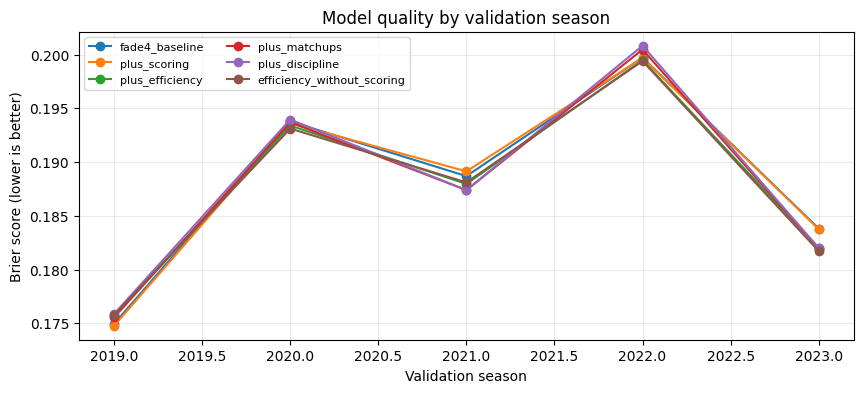

In [ ]:
pooled=pd.DataFrame([
    {'model':name,**evaluate(group.home_win,group.predicted_p_home_win)}
    for name,group in oof.groupby('model')
]).sort_values('brier').reset_index(drop=True)
print('Overall pooled validation performance (lower Brier is better):')
display(pooled.round(5))

briers=fold_scores.pivot(index='validation_season',columns='model',values='brier')
deltas=briers.sub(briers['fade4_baseline'],axis=0)
print('Per-season Brier differences versus Fade 4; negative is an improvement:')
display(deltas.round(6))

best=pooled.iloc[0]['model']
base=oof.loc[oof.model.eq('fade4_baseline'),['game_id','home_win','predicted_p_home_win']].rename(
    columns={'predicted_p_home_win':'p_base'})
choice=oof.loc[oof.model.eq(best),['game_id','predicted_p_home_win']].rename(
    columns={'predicted_p_home_win':'p_choice'})
paired=base.merge(choice,on='game_id',how='inner',validate='one_to_one')
assert len(paired)==3646
paired['brier_improvement']=(paired.home_win-paired.p_base)**2-(paired.home_win-paired.p_choice)**2
print('Best pooled model:',best)
print('Paired mean squared-error reduction vs Fade 4:',paired.brier_improvement.mean())
print('Number of games helped:',int((paired.brier_improvement>0).sum()),
      '| harmed:',int((paired.brier_improvement<0).sum()),
      '| equal:',int((paired.brier_improvement==0).sum()))

fig,ax=plt.subplots(figsize=(10,4))
for name in FEATURE_SETS:
    ax.plot(briers.index,briers[name],marker='o',label=name)
ax.set_xlabel('Validation season');ax.set_ylabel('Brier score (lower is better)')
ax.set_title('Model quality by validation season')
ax.legend(loc='best',fontsize=8,ncol=2);ax.grid(alpha=.25)
plt.show()

## 7. Diagnostic: performance by point in the season



In [ ]:
stage_order=list(history_manifest['stage_labels'])
stage_rows=[]
for (name,stage),part in oof.groupby(['model','season_stage'],observed=False):
    if part.empty: continue
    stage_rows.append({'model':name,'season_stage':stage,**evaluate(part.home_win,part.predicted_p_home_win)})
by_stage=pd.DataFrame(stage_rows)
print('Brier score by season stage:')
stage_pivot=by_stage.pivot(index='season_stage',columns='model',values='brier').reindex(stage_order)
display(stage_pivot.round(5))
print('Games in each season stage:')
display(by_stage.loc[by_stage.model.eq('fade4_baseline'),['season_stage','n_games']].set_index('season_stage').reindex(stage_order))
print('Comparison to Fade 4 by stage; negative differences are better:')
display(stage_pivot.sub(stage_pivot['fade4_baseline'],axis=0).round(5))

Brier score by season stage:


model,efficiency_without_scoring,fade4_baseline,plus_discipline,plus_efficiency,plus_matchups,plus_scoring
season_stage,,,,,,
0 FBS games,0.17827,0.17548,0.18204,0.17852,0.17972,0.17566
1–3 FBS games,0.18982,0.18893,0.19062,0.19013,0.19075,0.18950
4–7 FBS games,0.18783,0.19031,0.18710,0.18770,0.18715,0.19021
8+ FBS games,0.18754,0.18854,0.18742,0.18750,0.18745,0.18808


Games in each season stage:


,n_games
season_stage,
0 FBS games,400
1–3 FBS games,997
4–7 FBS games,1229
8+ FBS games,1020


Comparison to Fade 4 by stage; negative differences are better:


model,efficiency_without_scoring,fade4_baseline,plus_discipline,plus_efficiency,plus_matchups,plus_scoring
season_stage,,,,,,
0 FBS games,0.00280,0.0,0.00657,0.00304,0.00425,0.00018
1–3 FBS games,0.00089,0.0,0.00169,0.00120,0.00183,0.00057
4–7 FBS games,-0.00248,0.0,-0.00321,-0.00261,-0.00316,-0.00010
8+ FBS games,-0.00100,0.0,-0.00111,-0.00104,-0.00109,-0.00046


## 8. Save the experiment artifacts



In [ ]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
PROCESSED.mkdir(parents=True,exist_ok=True)
OUTPUT_FILES={
    'matchup_features':PROCESSED/'matchup_features_offense_defense.csv',
    'feature_manifest':PROCESSED/'offense_defense_feature_manifest.json',
    'fold_scores':OUTPUT_DIR/'offense_defense_fold_scores.csv',
    'pooled_scores':OUTPUT_DIR/'offense_defense_pooled_scores.csv',
    'oof_predictions':OUTPUT_DIR/'offense_defense_oof_predictions_2019_2023.csv',
    'scores_by_stage':OUTPUT_DIR/'offense_defense_scores_by_stage.csv',
    'yearly_brier_differences':OUTPUT_DIR/'offense_defense_brier_deltas_by_season.csv',
}
expanded.to_csv(OUTPUT_FILES['matchup_features'],index=False)
fold_scores.to_csv(OUTPUT_FILES['fold_scores'],index=False)
pooled.to_csv(OUTPUT_FILES['pooled_scores'],index=False)
oof.to_csv(OUTPUT_FILES['oof_predictions'],index=False)
by_stage.to_csv(OUTPUT_FILES['scores_by_stage'],index=False)
deltas.to_csv(OUTPUT_FILES['yearly_brier_differences'])
manifest={
    'experiment':'Notebook 09 offensive, defensive and matchup efficiency',
    'starting_model':'Notebook 07 prior_3seasons_fade4',
    'feature_sets':FEATURE_SETS,
    'raw_statistic_columns':REQUIRED,
    'pregame_rule':'previous same-team same-season games versus verified FBS opponents only',
    'ratio_rule':'sum valid previous FBS numerators / sum corresponding denominators',
    'yards_per_play_caveat':'proxy = total yards/(rush attempts + pass attempts); not play-by-play EPA',
    'fumble_rule':'excluded until fum variable semantics verified',
    'primary_metric':'pooled out-of-fold Brier score',
    'folds':folds,
    'test_seasons_reserved':sorted(TEST_SEASONS),
    'software':{'pandas':pd.__version__,'scikit_learn':sklearn.__version__},
    'baseline_reproduction_diagnostics':reproduction,
    'interpretation':'2019–2023 reused for exploratory model development; final test was not scored.'
}
OUTPUT_FILES['feature_manifest'].write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved artifacts:')
for key,path in OUTPUT_FILES.items(): print(f'  {key}: {path}')
print('Reminder: 2024–2025 final-test outcomes remain reserved.')

Saved artifacts:
  matchup_features: /content/drive/MyDrive/CFB_Upset_Project/data/processed/matchup_features_offense_defense.csv
  feature_manifest: /content/drive/MyDrive/CFB_Upset_Project/data/processed/offense_defense_feature_manifest.json
  fold_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/offense_defense_fold_scores.csv
  pooled_scores: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/offense_defense_pooled_scores.csv
  oof_predictions: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/offense_defense_oof_predictions_2019_2023.csv
  scores_by_stage: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/offense_defense_scores_by_stage.csv
  yearly_brier_differences: /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/offense_defense_brier_deltas_by_season.csv
Reminder: 2024–2025 final-test outcomes remain reserved.
